# 🚕 Q-Learning en Taxi-v4 — Trabajo en casa

En este ejercicio aplicará Q-Learning al ambiente **Taxi-v4** de Gymnasium.

La lógica es la misma trabajada en FrozenLake:

$$
(s_t,a_t) \rightarrow (r_{t+1},s_{t+1})
$$

y la actualización:

$$
Q(s_t,a_t)
\leftarrow
Q(s_t,a_t)
+
\alpha
\left[
r_{t+1}
+
\gamma \max_a Q(s_{t+1},a)
-
Q(s_t,a_t)
\right]
$$

## Objetivo

Implementar y analizar un agente Q-Learning capaz de aprender a recoger un pasajero y llevarlo a su destino.


## 1. Preparación

Instale Gymnasium si es necesario:

```bash
pip install gymnasium[toy-text]
```


In [1]:
import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt

from IPython.display import HTML
from matplotlib import animation

## 2. Crear el ambiente

Taxi tiene un número de estados mucho mayor que FrozenLake.

Cada estado codifica:

- posición del taxi,
- ubicación del pasajero,
- destino del pasajero.

Las acciones posibles son:

| Acción | Significado |
|---|---|
| 0 | South |
| 1 | North |
| 2 | East |
| 3 | West |
| 4 | Pickup |
| 5 | Dropoff |


In [2]:
env = gym.make("Taxi-v4", render_mode="rgb_array")

print("Número de estados:", env.observation_space.n)
print("Número de acciones:", env.action_space.n)

Número de estados: 500
Número de acciones: 6


### Pregunta 1

¿Cuántos estados y cuántas acciones tiene Taxi-v4?

Explique brevemente por qué Taxi tiene muchos más estados que FrozenLake.


**Respuesta:**

Taxi-v4 tiene **500 estados** y **6 acciones** (sur, norte, este, oeste, recoger y dejar).

Los 500 salen de combinar las tres cosas que cambian en el problema: 25 posiciones posibles del taxi en la cuadrícula de 5×5, 5 ubicaciones del pasajero (las 4 paradas más "dentro del taxi") y 4 destinos posibles: 25 × 5 × 4 = 500. FrozenLake en su versión 4×4 solo tiene 16 estados porque el estado es únicamente la posición del agente; no hay pasajero ni destino que cambien la situación.

## 3. Observar una interacción

Ejecute una acción aleatoria y observe qué devuelve el ambiente.


In [3]:
state, info = env.reset(seed=42)

action = env.action_space.sample()

next_state, reward, terminated, truncated, info = env.step(action)

print("Estado:", state)
print("Acción:", action)
print("Nuevo estado:", next_state)
print("Recompensa:", reward)
print("Terminated:", terminated)

Estado: 386
Acción: 3
Nuevo estado: 366
Recompensa: -1
Terminated: False


### Pregunta 2

En la interacción anterior identifique:

$$
s_t,\quad a_t,\quad r_{t+1},\quad s_{t+1}
$$

¿Qué representa cada elemento?


**Respuesta:**

- $s_t$: el estado antes de actuar. Es un entero entre 0 y 499 que codifica la posición del taxi, dónde está el pasajero y cuál es el destino (en la ejecución de arriba, el 386).
- $a_t$: la acción que se tomó, un entero entre 0 y 5. Aquí se sacó al azar con `env.action_space.sample()`.
- $r_{t+1}$: la recompensa que devuelve el ambiente por esa acción. En Taxi es -1 por cada paso normal, +20 al dejar al pasajero en su destino y -10 si se intenta recoger o dejar donde no se puede.
- $s_{t+1}$: el estado en el que queda el taxi después de la acción (en el ejemplo, el 486, que es el taxi una fila más abajo porque la acción fue ir al sur).

## 4. Inicializar la Q-table

Cada fila corresponde a un estado y cada columna a una acción.

Inicialmente:

$$
Q(s,a)=0
$$


In [4]:
n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

print("Shape de Q:", Q.shape)
Q[:5]

Shape de Q: (500, 6)


array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

### Pregunta 3

¿Cuántos valores debe aprender el agente en total?

Calcule:

$$
|\mathcal{S}| \times |\mathcal{A}|
$$


**Respuesta:**

$|\mathcal{S}| \times |\mathcal{A}| = 500 \times 6 = 3000$ valores. Es justo el tamaño de la Q-table, `Q.shape = (500, 6)`. Sigue siendo manejable en una tabla, pero ya se nota por qué en problemas con más variables la tabla deja de servir.

## 5. Política $\epsilon$-greedy

Implemente una función que:

- con probabilidad $\epsilon$ seleccione una acción aleatoria;
- en otro caso seleccione:

$$
\arg\max_a Q(s,a)
$$

### Actividad 1
Complete la función.


In [5]:
def choose_action(Q, state, epsilon, env):
    if random.random() < epsilon:
        return env.action_space.sample()

    q_values = Q[state]
    best_actions = np.flatnonzero(q_values == np.max(q_values))
    return int(np.random.choice(best_actions))

## 6. Actualización de Q

La regla de actualización es:

$$
Q(s,a)
\leftarrow
Q(s,a)
+
\alpha
\left[
r+
\gamma\max_{a'}Q(s',a')
-
Q(s,a)
\right]
$$

### Actividad 2
Complete la función.


In [6]:
def update_q(Q, state, action, reward, next_state, alpha, gamma):
    target = reward + gamma * np.max(Q[next_state])

    td_error = target - Q[state, action]

    Q[state, action] += alpha * td_error

    return Q

## 7. Entrenamiento

Ahora implemente el ciclo completo de Q-Learning.

En cada episodio:

1. reiniciar el ambiente;
2. escoger una acción;
3. ejecutar `env.step(action)`;
4. actualizar $Q(s,a)$;
5. mover el agente a `next_state`;
6. terminar cuando el episodio finalice.

Use inicialmente:

```python
alpha = 0.1
gamma = 0.95
epsilon = 0.1
episodes = 5000
```

### Actividad 3
Complete la función.


In [7]:
def train_q_learning(
    env,
    Q,
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1,
    max_steps=200
):
    rewards = []

    for episode in range(episodes):
        state, _ = env.reset()
        total_reward = 0

        for _ in range(max_steps):

            action = choose_action(Q, state, epsilon, env)

            next_state, reward, terminated, truncated, _ = env.step(action)

            update_q(Q, state, action, reward, next_state, alpha, gamma)

            state = next_state
            total_reward += reward

            if terminated or truncated:
                break

        rewards.append(total_reward)

    return Q, rewards

## 8. Entrenar el agente

Ejecute el entrenamiento una vez haya completado las funciones anteriores.


In [8]:
random.seed(42); np.random.seed(42); env.action_space.seed(42)

Q_initial = np.zeros((n_states, n_actions))

Q_trained, rewards = train_q_learning(
    env,
    Q_initial.copy(),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1
)

## 9. Curva de aprendizaje

Observe cómo cambia la recompensa durante el entrenamiento.


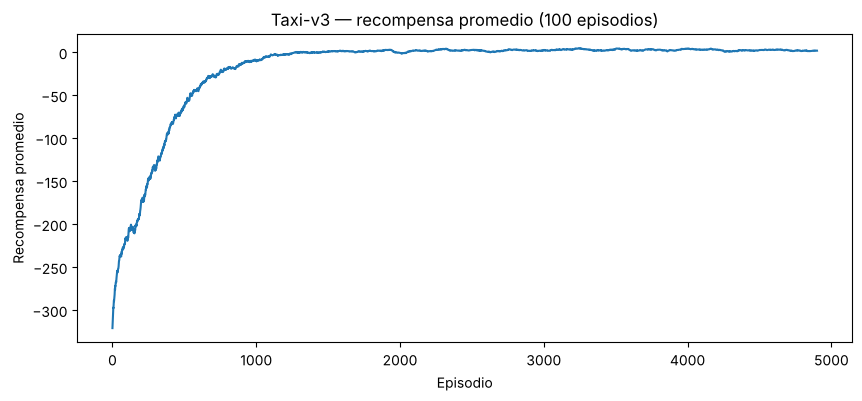

In [9]:
window = 100

moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 4))
plt.plot(moving_average)
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Taxi-v3 — recompensa promedio ({window} episodios)")
plt.show()

In [10]:
print("Recompensa promedio primeros 100 episodios:", round(np.mean(rewards[:100]), 1))
print("Recompensa promedio últimos 500 episodios :", round(np.mean(rewards[-500:]), 2))
for umbral in (-50, -10, 0):
    idx = np.flatnonzero(moving_average > umbral)
    print(f"Media móvil supera {umbral:>4}: episodio", int(idx[0]) if len(idx) else None)

Recompensa promedio primeros 100 episodios: -320.9
Recompensa promedio últimos 500 episodios : 2.37
Media móvil supera  -50: episodio 539
Media móvil supera  -10: episodio 940
Media móvil supera    0: episodio 1271


### Pregunta 4

Describa la curva de aprendizaje.

- ¿La recompensa promedio mejora?
- ¿Después de aproximadamente cuántos episodios comienza a estabilizarse?
- ¿El comportamiento observado indica convergencia perfecta o solamente una política razonablemente buena?


**Respuesta:**

Sí mejora, y mucho. En los primeros 100 episodios la recompensa promedio fue de unos -321 (el taxi da vueltas al azar hasta que se acaban los 200 pasos, y además se come penalizaciones de -10 por recoger o dejar mal), y en los últimos 500 episodios quedó en aproximadamente +2.4.

Con la media móvil de 100 episodios, la curva supera -50 hacia el episodio 540, supera -10 cerca del 940 y pasa de 0 alrededor del 1270. Después de unos 1500 episodios se ve casi plana, así que ahí es donde empieza a estabilizarse.

No lo llamaría convergencia perfecta. Durante el entrenamiento seguimos usando $\epsilon = 0.1$, entonces 1 de cada 10 acciones sigue siendo aleatoria y eso hace que la curva oscile (la desviación de los últimos 500 episodios es de 7.5 aprox.). Lo que tenemos es una política razonablemente buena, no necesariamente la óptima en todos los estados.

## 10. Reproducir un episodio

La siguiente función ejecuta una política greedy usando la Q-table aprendida y guarda los frames del episodio.


In [11]:
def play_episode(env, Q, max_steps=200, seed=None):
    state, _ = env.reset(seed=seed)

    frames = [env.render()]
    total_reward = 0

    for _ in range(max_steps):

        q_values = Q[state]
        max_q = np.max(q_values)

        best_actions = np.flatnonzero(q_values == max_q)
        action = int(np.random.choice(best_actions))

        next_state, reward, terminated, truncated, _ = env.step(action)

        frames.append(env.render())

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    return frames, total_reward

def frames_to_video(frames, interval=500):
    fig = plt.figure(figsize=(6, 4))
    plt.axis("off")

    image = plt.imshow(frames[0])

    def update(frame):
        image.set_data(frame)
        return [image]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=interval,
        blit=True,
        repeat=True
    )

    plt.close(fig)
    return HTML(anim.to_jshtml())

## 11. Comparar antes y después

Primero observe un Taxi sin entrenamiento usando una Q-table en cero.


In [12]:
frames_initial, reward_initial = play_episode(
    env,
    Q_initial,
    max_steps=50,
    seed=7
)

print("Recompensa total sin entrenamiento:", reward_initial)
frames_to_video(frames_initial, interval=500)

error: XDG_RUNTIME_DIR is invalid or not set in the environment.


Recompensa total sin entrenamiento: -212


Ahora observe el agente entrenado.


In [13]:
frames_trained, reward_trained = play_episode(
    env,
    Q_trained,
    max_steps=200,
    seed=7
)

print("Recompensa total después del entrenamiento:", reward_trained)
frames_to_video(frames_trained, interval=500)

Recompensa total después del entrenamiento: 10


### Pregunta 5

Compare los dos episodios.

- ¿Qué diferencias observa en el comportamiento del taxi?
- ¿El taxi sin entrenamiento logra completar la tarea?
- ¿El agente entrenado evita acciones innecesarias?
- ¿Qué evidencia visual le permite afirmar que el agente aprendió?


**Respuesta:**

El taxi sin entrenar se mueve sin sentido: choca contra las paredes, intenta recoger o dejar al pasajero donde no se puede y no completa la tarea; con la Q-table en ceros siempre elige entre empates al azar, y en la ejecución con `seed=7` terminó con una recompensa de -212 (se acabaron los pasos sin entregar a nadie).

El taxi entrenado va directo hacia el pasajero, lo recoge, lo lleva al destino y lo deja, y termina el episodio con recompensa de +10 en muy pocos pasos. Evita movimientos innecesarios, y esa es la evidencia visual más clara de que aprendió: la ruta es corta y directa, y el episodio termina por entrega exitosa y no por llegar al límite de pasos.

## 12. Analizar la política aprendida

Seleccione un estado cualquiera y observe los valores aprendidos para sus seis acciones.


In [14]:
state = 123

print("Estado:", state)
print("Q-values:", Q_trained[state])
print("Mejor acción:", np.argmax(Q_trained[state]))

Estado: 123
Q-values: [-1.81106978 -2.88438838 -1.64110416  3.94947757 -5.96415135 -6.24256667]
Mejor acción: 3


### Pregunta 6

Para el estado seleccionado:

1. ¿Cuál es la acción con mayor valor Q?
2. ¿Qué significa que una acción tenga un valor Q mayor que otra?
3. ¿Por qué no podemos interpretar $Q(s,a)$ únicamente como la recompensa inmediata de ejecutar la acción?


**Respuesta:**

1. En el estado 123 los valores aprendidos son aproximadamente `[-1.81, -2.88, -1.64, 3.95, -5.96, -6.24]`, así que la mejor acción es la **3 (West)**, con Q ≈ 3.95.
2. Que una acción tenga un Q mayor significa que, desde ese estado, ese movimiento es el que más recompensa total esperada deja si después se sigue actuando bien. Es una comparación de qué tan buenas son las acciones desde ese estado.
3. Porque $Q(s,a)$ no mide solo lo que pasa en el paso inmediato, sino la recompensa descontada de todo lo que viene después. Un ejemplo claro es que ir al oeste tiene recompensa inmediata de -1, igual que casi cualquier otro movimiento, pero termina siendo la mejor porque acerca al taxi al pasajero y a la entrega de +20 más adelante. Los valores de recoger/dejar (-5.96 y -6.24) son muy negativos porque en ese estado esas acciones fallan y cuestan -10.

## 13. Experimentación

Modifique **solo uno** de los siguientes hiperparámetros y vuelva a entrenar:

- $\alpha$
- $\gamma$
- $\epsilon$

### Pregunta 7

Compare el nuevo entrenamiento con el original.

Explique cómo el cambio del hiperparámetro afectó:

- velocidad de aprendizaje,
- estabilidad,
- recompensa final,
- comportamiento observado.


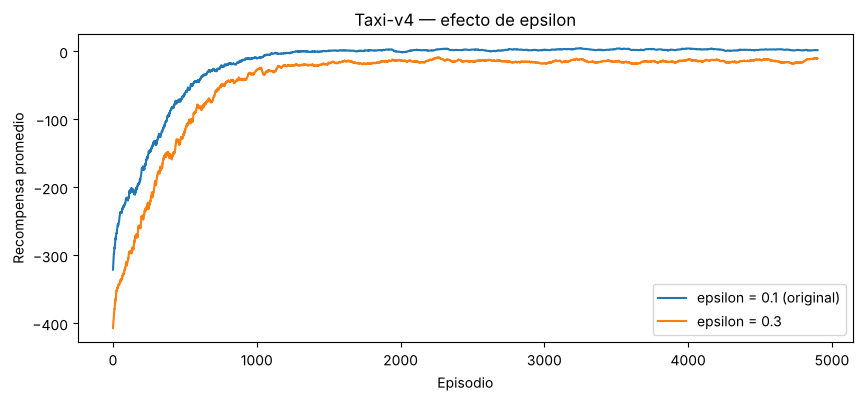

Epsilon 0.1 | cruza 0 en el episodio: 1271 | promedio últimos 500: 2.37 | desv. últimos 500: 7.52
Epsilon 0.3 | cruza 0 en el episodio: None | promedio últimos 500: -13.55 | desv. últimos 500: 17.28
Evaluación greedy (100 episodios) | eps 0.1: 7.63 | eps 0.3: 7.63


In [15]:
random.seed(42); np.random.seed(42); env.action_space.seed(42)
Q_exp, rewards_exp = train_q_learning(
    env, np.zeros((n_states, n_actions)),
    episodes=5000, alpha=0.1, gamma=0.95, epsilon=0.3
)

ma_exp = np.convolve(rewards_exp, np.ones(window) / window, mode="valid")

plt.figure(figsize=(10, 4))
plt.plot(moving_average, label="epsilon = 0.1 (original)")
plt.plot(ma_exp, label="epsilon = 0.3")
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title("Taxi-v4 — efecto de epsilon")
plt.legend()
plt.show()

def primer_episodio_estable(ma, umbral=0):
    idx = np.flatnonzero(ma > umbral)
    return int(idx[0]) if len(idx) else None

print("Epsilon 0.1 | cruza 0 en el episodio:", primer_episodio_estable(moving_average),
      "| promedio últimos 500:", round(np.mean(rewards[-500:]), 2),
      "| desv. últimos 500:", round(np.std(rewards[-500:]), 2))
print("Epsilon 0.3 | cruza 0 en el episodio:", primer_episodio_estable(ma_exp),
      "| promedio últimos 500:", round(np.mean(rewards_exp[-500:]), 2),
      "| desv. últimos 500:", round(np.std(rewards_exp[-500:]), 2))

def evaluar(Q, n=100):
    tot = []
    for k in range(n):
        s, _ = env.reset(seed=1000 + k)
        r_ep = 0
        for _ in range(200):
            s, r, te, tr, _ = env.step(int(np.argmax(Q[s])))
            r_ep += r
            if te or tr: break
        tot.append(r_ep)
    return np.mean(tot)

print("Evaluación greedy (100 episodios) | eps 0.1:", round(evaluar(Q_trained), 2),
      "| eps 0.3:", round(evaluar(Q_exp), 2))

### Pregunta 7 — Respuesta

Cambié solo $\epsilon$ de 0.1 a 0.3 (alpha = 0.1 y gamma = 0.95 igual que antes).

- **Velocidad de aprendizaje:** con $\epsilon = 0.3$ el promedio móvil nunca llega a cruzar 0, mientras que con 0.1 lo hizo cerca del episodio 1270. La recompensa de entrenamiento mejora más lento.
- **Estabilidad:** es bastante menos estable. La desviación de la recompensa en los últimos 500 episodios subió de 7.5 a 17.3, porque con 30 % de acciones aleatorias cualquier episodio se puede arruinar con un par de recogidas o entregas fallidas (-10 cada una).
- **Recompensa final (en entrenamiento):** quedó en -13.6 en promedio contra +2.4 con $\epsilon = 0.1$. Ojo con esto: esa diferencia es de lo que obtiene el agente *mientras explora*, no de qué tan buena quedó la política.
- **Comportamiento observado:** cuando evalué las dos Q-tables de forma greedy (sin exploración, 100 episodios con las mismas semillas), las dos dieron la misma recompensa promedio, 7.63. O sea que con 5000 episodios más exploración no empeoró la política aprendida; solo hizo que el entrenamiento se viera peor. Con tanta exploración el costo se paga en la curva de aprendizaje, y el beneficio (visitar más estados) no se necesitaba tanto en un ambiente tan pequeño.

## Entrega

El notebook debe contener:

1. implementación de `choose_action`;
2. implementación de `update_q`;
3. implementación de `train_q_learning`;
4. curva de aprendizaje;
5. visualización del agente antes y después del entrenamiento;
6. respuestas a las siete preguntas.

No es necesario modificar las funciones auxiliares de visualización.


---
### Declaración de uso de IA generativa

Herramienta: Claude (Anthropic). Propósito: asistencia en programación (completar `choose_action`, `update_q`, `train_q_learning`) y borrador de las respuestas, que revisé y ajusté contra los resultados del notebook.